# Who the Map Misses: two-minute demo

This notebook runs the whole pipeline on **synthetic data** with biases planted on purpose: a wealth map
that ranks Indigenous places as wealthier than they are, lower map coverage of Indigenous places, and
satellite features that make Indigenous places look less deprived. It shows that every step runs and that
the audit recovers the planted bias. **None of these numbers describe Mexico**; real results are on the
project website.

Runs in JupyterLab or Google Colab. The code it calls lives in `src/mapaudit/`.

In [1]:
# In Google Colab, fetch the project first; anywhere else this cell does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src/mapaudit").exists() and not Path("../src/mapaudit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/cody-allen-analytics/who-the-map-misses.git"], check=True)
    os.chdir("who-the-map-misses")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)

In [2]:
# Make the project importable; works in JupyterLab, VS Code and Colab without reinstalling.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src"))

%load_ext autoreload
%autoreload 2

import pandas as pd
from IPython.display import display

from mapaudit import notebook as nb
from mapaudit import pipeline, report
from mapaudit.config import get_paths

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)
MODE = "demo"  # this notebook always uses synthetic data
print("Mode:", MODE)

Mode: demo


## 1. Build a synthetic Mexico

A few thousand localities with census-style counts, a Relative-Wealth-Index-style map on 2.4 km tiles, and
64-dimensional satellite embeddings, all written in the same file formats as the real sources, so the
real-data code path is exercised.

In [3]:
summary = pipeline.build(MODE)
pd.Series({k: v for k, v in summary.items() if k != "label_loadings"}, name="value", dtype=object).to_frame()

,value
localities,6836
localities_in_scope,6733
localities_with_dwelling_data,5606
population,"3,679,177.000"
indigenous_localities,1695
rwi_tiles_in_file,5395
rwi_quadkey_consistency,1.000
rwi_tiles_matched,4464
localities_with_embeddings,6836
embedding_median_norm,0.799


## 2. Audit the map against the census

Rank error = map percentile − census percentile for each tile; above zero means the map ranks the place as
wealthier than the census does, i.e. it understates deprivation. Two views of the same errors:

- **Among equally poor places** (grouped by true decile): does the map treat Indigenous and non-Indigenous
  places alike? This is the confirmatory test (H2). It separates an Indigenous-specific blind spot from the
  general tendency of these maps to pull the poorest places toward the middle.
- **Among places the map ranks the same** (grouped by map decile): can someone using the map take its
  ranking at face value for both groups?

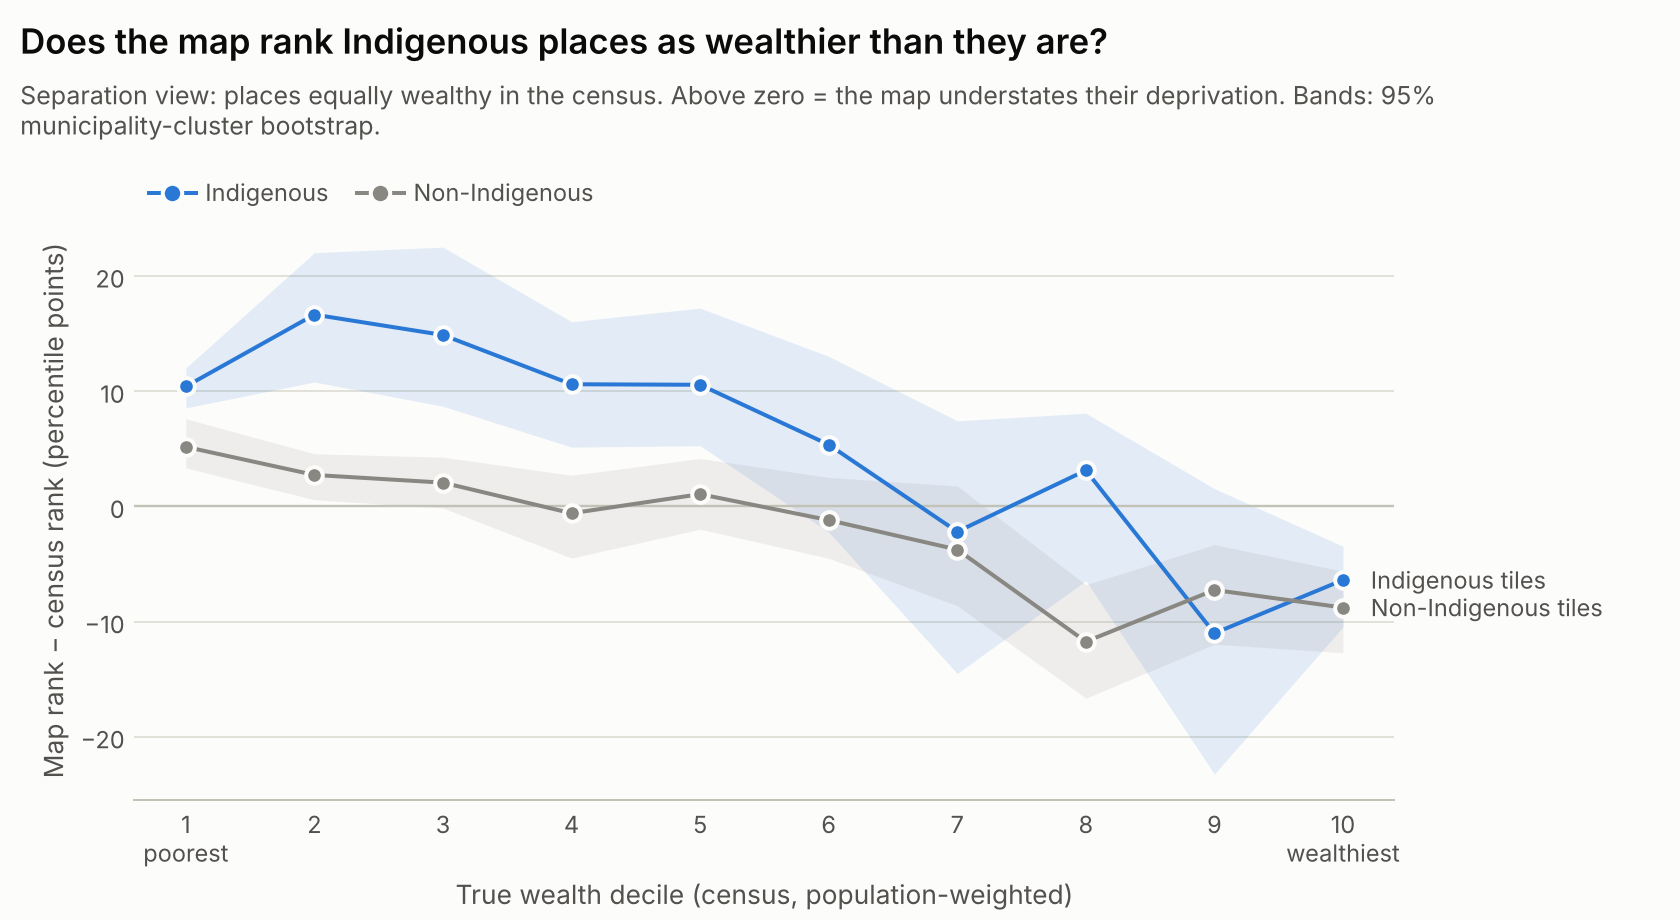

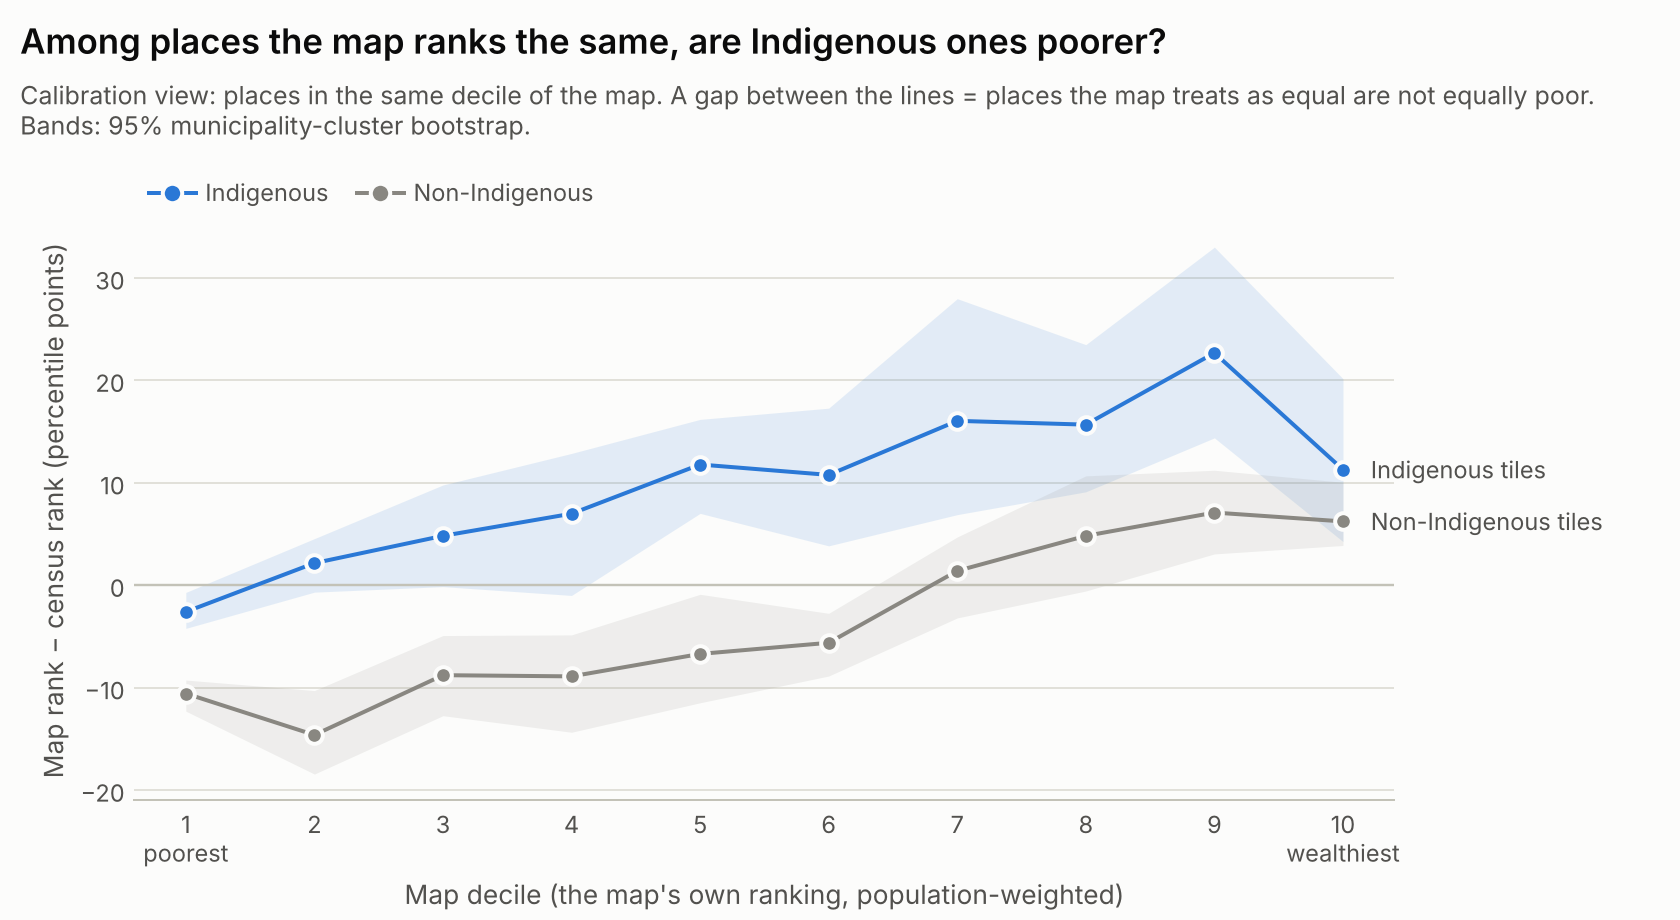

In [4]:
audit = pipeline.audit(MODE)
report.render_figures(MODE)
nb.show_figure("decile_errors", MODE)
nb.show_figure("map_decile_errors", MODE)

The two pre-registered tests, with Holm's correction because there are two:

In [5]:
tests = nb.load_table("confirmatory_tests", MODE)
tests[["p_value", "p_holm"]] = tests[["p_value", "p_holm"]].map("{:.1e}".format)  # p-values can be tiny
tests

,hypothesis,estimate,ci_low,ci_high,test,p_value,p_holm,supported_at_5pct
0,H1 coverage,-0.071,-0.111,-0.031,two-sided,5.4e-04,5.4e-04,True
1,H2 rank bias,20.255,15.055,25.456,one-sided (> 0),1.1e-14,2.3e-14,True


How the Indigenous coefficient changes as controls are added (the last row is H2):

In [6]:
nb.load_table("audit_regressions", MODE).round(2)

,spec,term,coef,se,ci_low,ci_high,p_value,p_one_sided,n
0,1 none,ind_share,26.950,2.190,22.660,31.240,0.000,0.000,4452
1,2 + rurality,ind_share,26.560,2.150,22.330,30.780,0.000,0.000,4452
2,3 + remoteness,ind_share,26.240,2.300,21.730,30.740,0.000,0.000,4452
3,4 + true decile,ind_share,20.700,2.240,16.320,25.080,0.000,0.000,4452
4,5 + state FE,ind_share,20.260,2.650,15.050,25.460,0.000,0.000,4452


Pre-specified robustness checks:

In [7]:
pipeline.robustness(MODE).round(2)

,variant,rank_error_coef,ci_low,ci_high,p_value,decile_conditional_gap_pp,tiles
0,Primary specification,20.260,15.050,25.460,0.000,8.600,4452
1,Unweighted,19.820,17.210,22.430,0.000,8.600,4452
2,Tiles with 50+ people,20.290,14.530,26.050,0.000,8.600,2488
3,Indigenous threshold 30%,20.260,15.050,25.460,0.000,7.860,4452
4,Indigenous threshold 50%,20.260,15.050,25.460,0.000,10.120,4452
5,Ground truth: infrastructure deprivation,29.190,23.750,34.630,0.000,11.970,4452
6,Ground truth: marginalization index,34.650,29.270,40.020,0.000,14.140,4452
7,Language-based Indigenous share,23.790,17.670,29.910,0.000,8.930,4452


## 3. Can the audit be trusted?

Two synthetic worlds: one with a planted Indigenous bias, one without. A trustworthy audit finds the bias
in the first and nothing in the second.

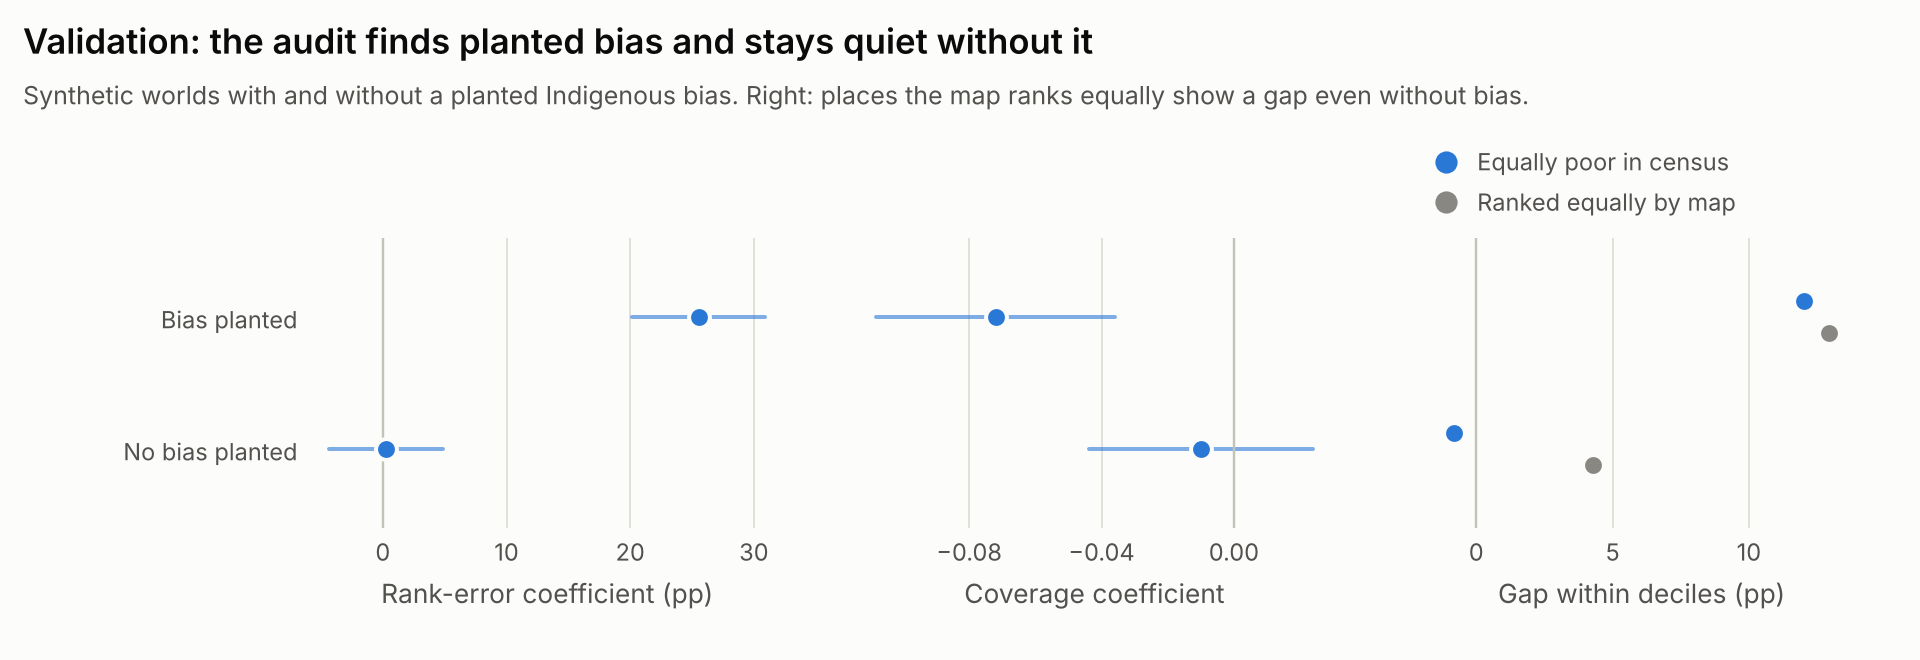

,world,planted_rwi_bias_sd,planted_coverage_logit,rank_error_coef,rank_error_ci_low,rank_error_ci_high,separation_gap_pp,calibration_gap_pp,coverage_coef,coverage_ci_low,coverage_ci_high
0,Bias planted,0.600,-0.800,25.550,20.170,30.930,12.020,12.930,-0.070,-0.110,-0.040
1,No bias planted,0.000,0.000,0.240,-4.350,4.840,-0.800,4.290,-0.010,-0.040,0.020


In [8]:
validation = pipeline.validate()
report.render_figures(MODE)
nb.show_figure("validation", MODE)
validation.round(2)

Compare the two gap columns in the world without bias. Among equally poor places the gap is near zero, as it
should be. Among places the map ranks the same it is not, even though the map's errors ignore group: the
groups differ in average wealth, so places that look alike on the map are, on average, poorer if they are
Indigenous. That is why the confirmatory test uses the first view, and why the second is reported against
this benchmark.

## 4. Challenger models trained on a simulated survey

A realistic survey is drawn from the census; models are trained on it and scored on localities it never
visited. Small area estimation (Fay-Herriot) borrows strength from the survey's municipalities;
plain gradient boosting does not.

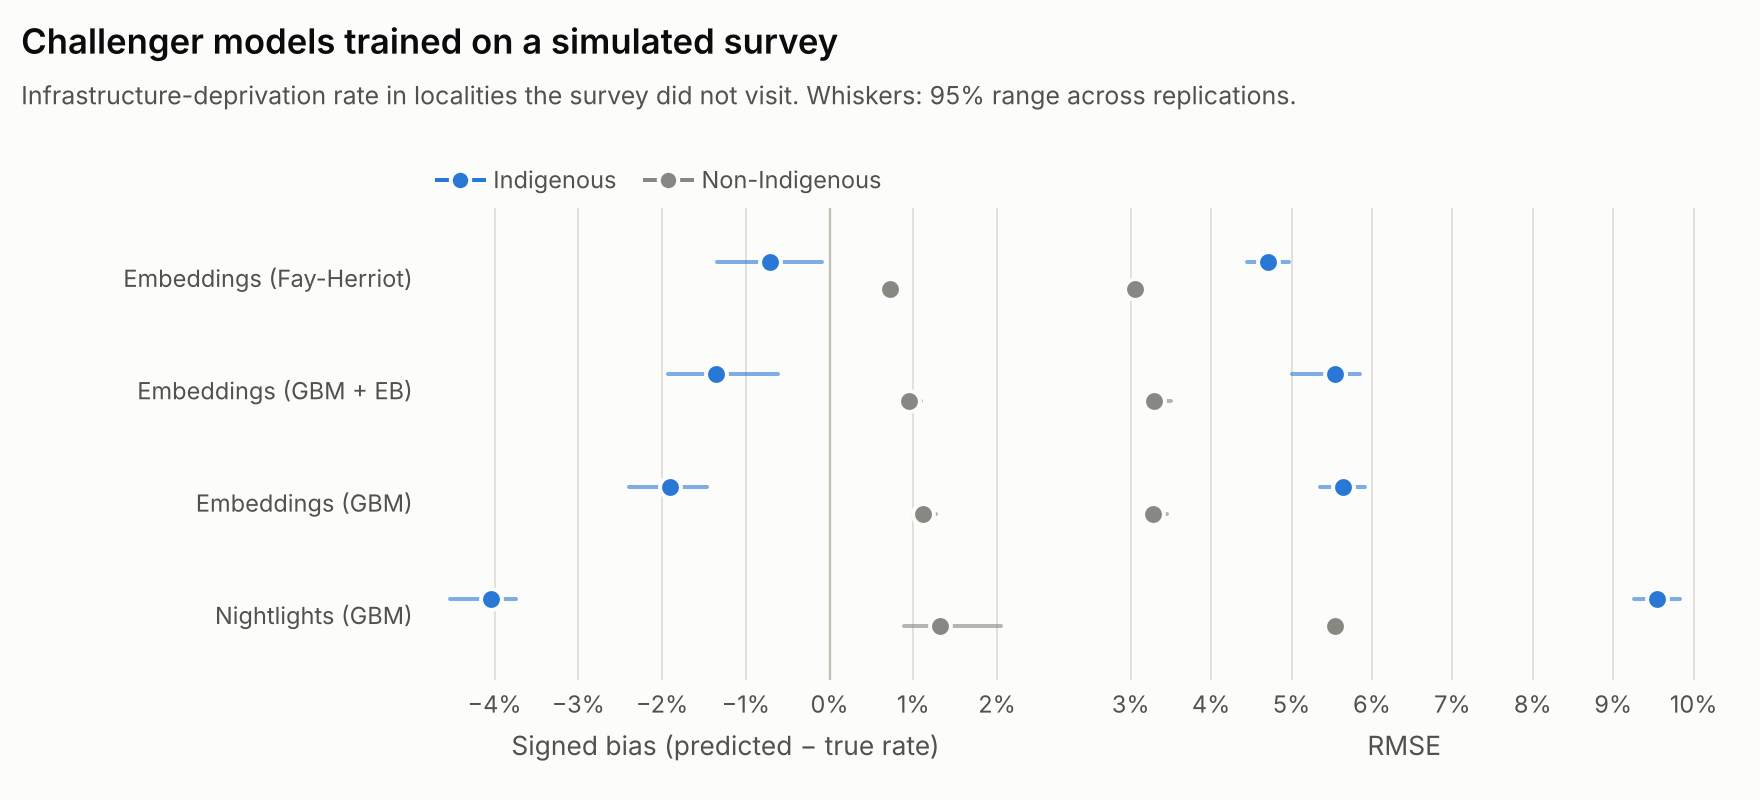

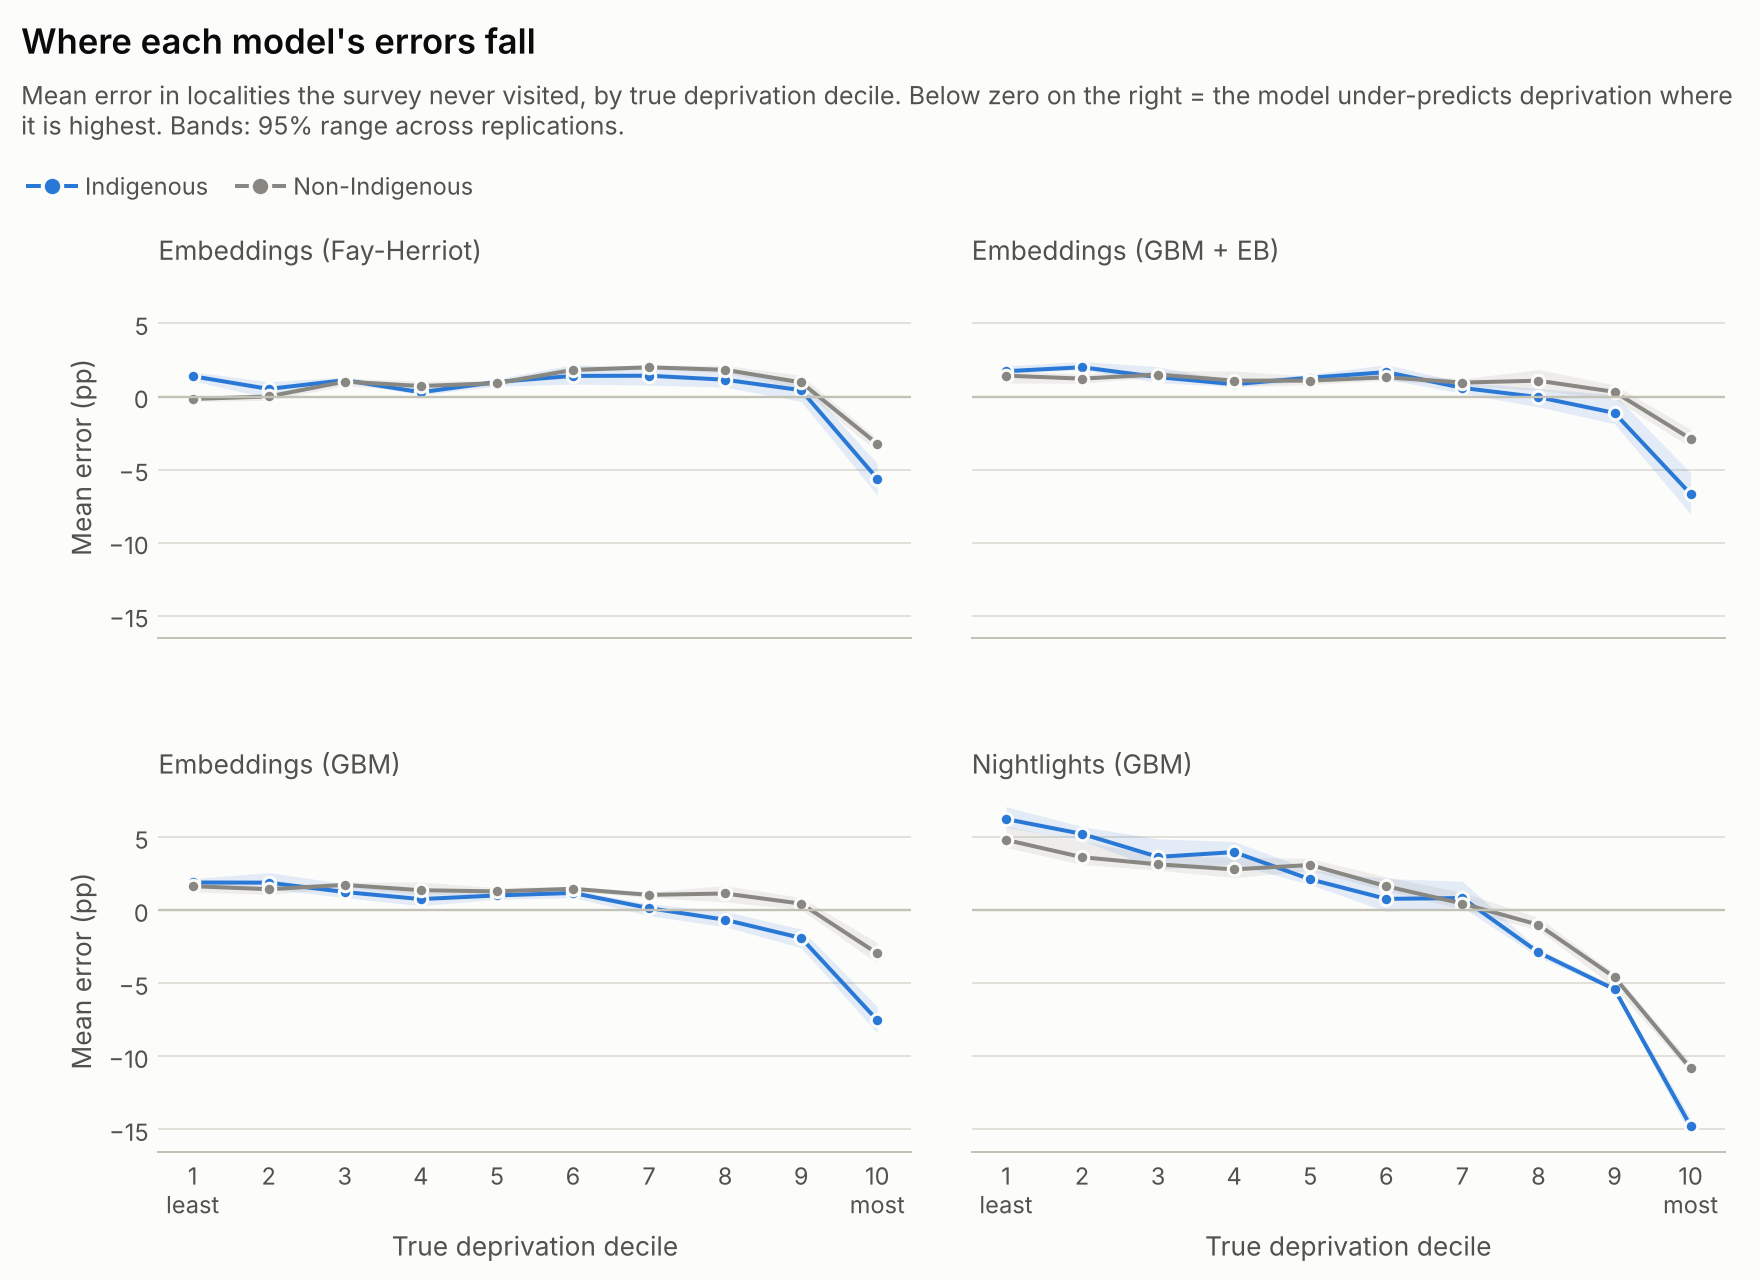

In [9]:
pipeline.simulate(MODE)
report.render_figures(MODE)
nb.show_figure("challenger_bias", MODE)
nb.show_figure("challenger_deciles", MODE)

H4 as pre-registered: the difference in absolute bias for Indigenous localities, gradient boosting minus
small area estimation, computed on the same simulated survey in each replication:

In [10]:
paired = nb.load_table("challenger_paired", MODE)
paired.loc[paired["hypothesis"] == "H4", ["metric", "model_a", "model_b", "mean_difference", "p025", "p975", "supported"]]

,metric,model_a,model_b,mean_difference,p025,p975,supported
0,|bias|,Embeddings (GBM),Embeddings (Fay-Herriot),0.012,0.009,0.014,yes


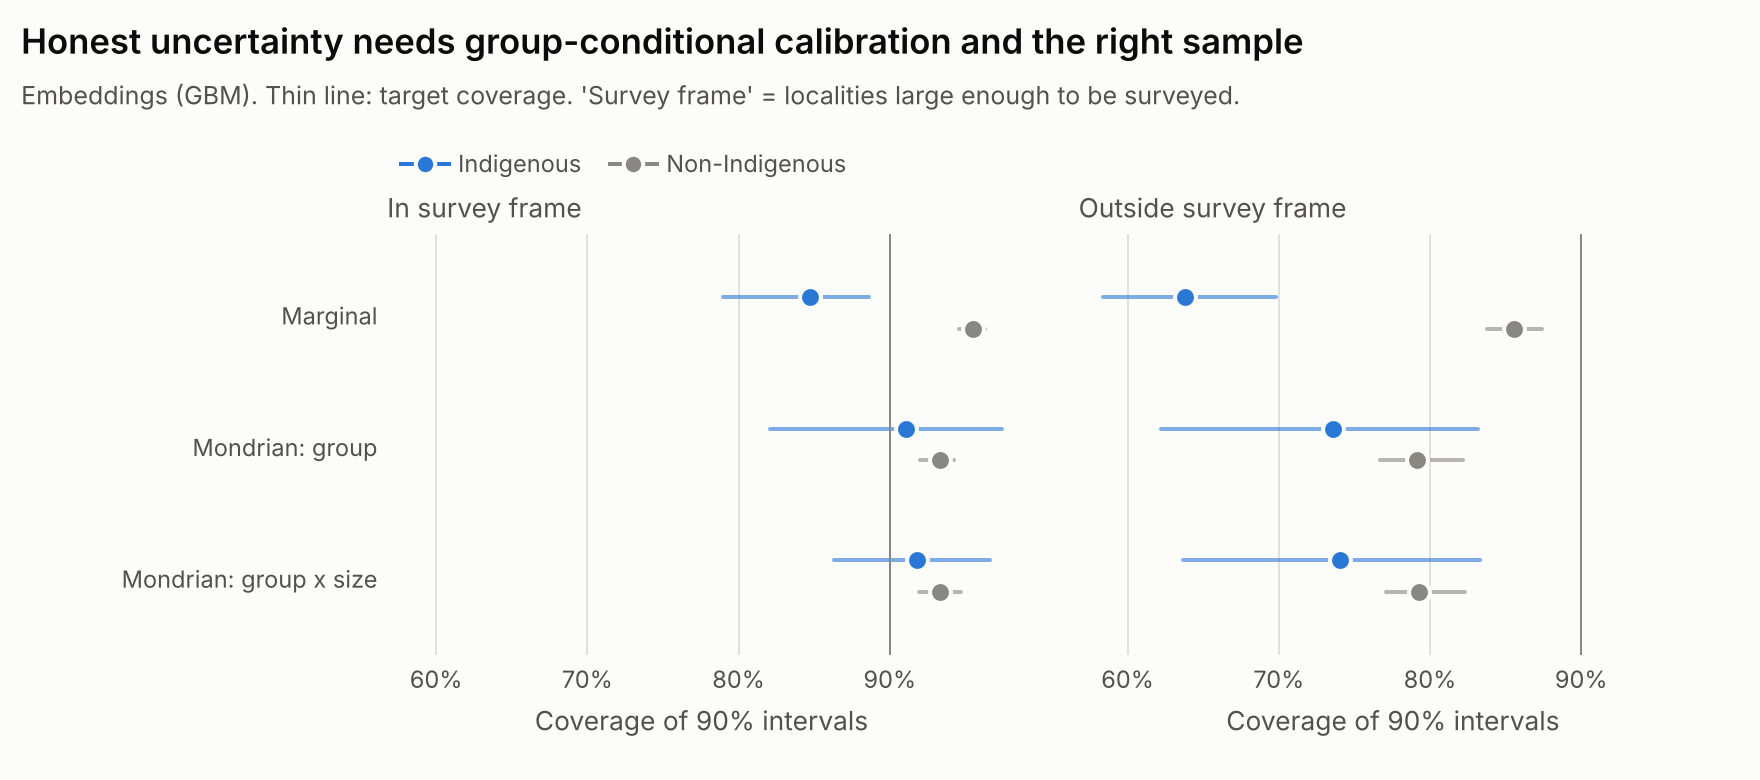

In [11]:
nb.show_figure("conformal_coverage", MODE)

## 5. What the errors cost

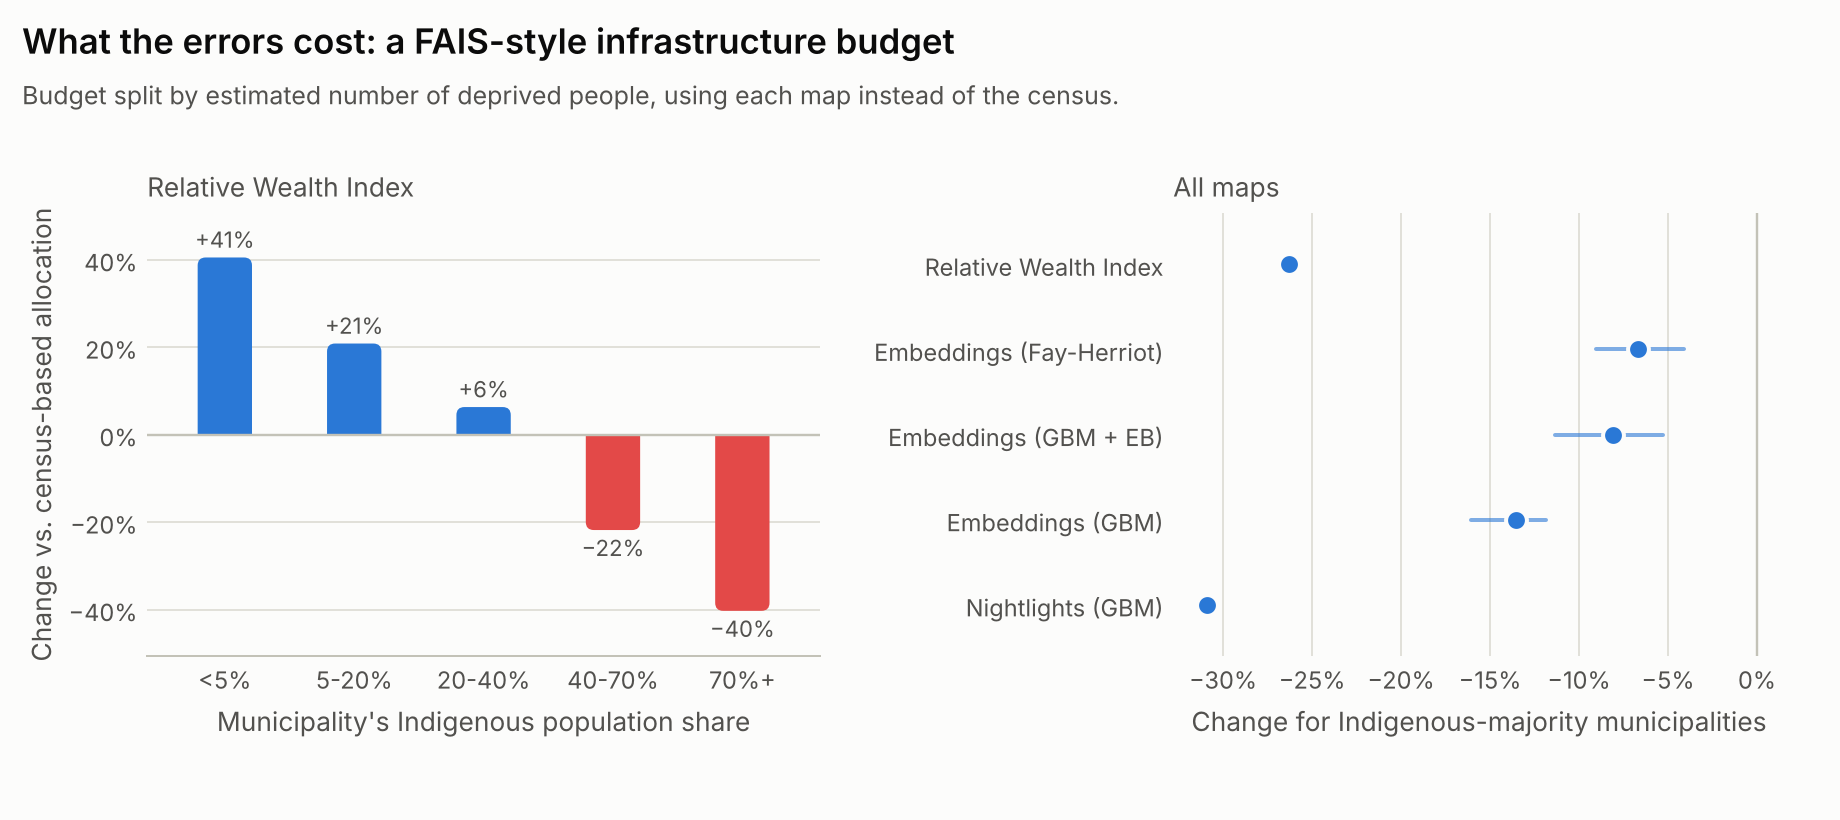

,group,municipalities,true_allocation,map_allocation,net_shift,net_shift_pct,shift_per_capita
0,Other municipalities,116,"612,187,789.485","714,270,030.617","102,082,241.132",0.167,172.567
1,Indigenous-majority municipalities,34,"387,812,210.515","285,729,969.383","-102,082,241.132",-0.263,-514.743


,group,misallocation_share,ape_median,ape_mean,municipalities
0,All,0.116,0.230,0.246,150
1,Indigenous-majority municipalities,NaN,0.255,0.250,34
2,Other municipalities,NaN,0.207,0.245,116


In [12]:
nb.show_figure("allocation", MODE)
display(nb.load_table("rwi_allocation", MODE).round(3))
nb.load_table("rwi_allocation_errors", MODE).round(3)

## Next

Notebooks 02-06 run the same steps on real data: the 2020 census, Meta's Relative Wealth Index and
Google DeepMind's AlphaEarth embeddings.